<div style="text-align: center;">

  <img src="img/LogoUesc.png" alt="UESC" style="width: 60px; display: block; margin: 0 auto 5px auto;">

  <div style="font-size: 20px;"><strong>UNIVERSIDADE ESTADUAL DE SANTA CRUZ - UESC</strong></div>
  <div style="font-size: 18px;">DEPARTAMENTO DE ENGENHARIAS E COMPUTAÇÃO - DEC</div>
  <div style="font-size: 18px;">Grupo de Pesquisas em Simulações e Controle de Processos</div>

  <hr style="margin: 20px 0; border: 1px solid #0074B7;">

  <div style="font-size: 22px; font-weight: bold; margin-bottom: 10px;">PROGRAMAÇÃO EM PYTHON PARA AS ENGENHARIAS</div>

  <div style="font-size: 18px; margin-top: 10px;"><strong>Tema</strong>: Mecânica dos Fluidos com Python — Escoamento, Perda de Carga e Bombeamento.</div>
  <div style="font-size: 18px;"><strong>Prof.  Dr.  E. R. Edwards</strong></div>

  <div style="font-size: 16px; margin-top: 15px;">Ilhéus - BA, Abril de 2027</div>
  
  <hr style="margin: 20px 0; border: 1px solid #0074B7;">

</div>

**Apresentação**

A Mecânica dos Fluidos permite relacionar propriedades dos fluidos, geometria de tubulações e condições operacionais com vazões, pressões e energia requerida para transportar líquidos. Neste notebook, estudaremos modelos introdutórios de escoamento interno e bombeamento, construindo as equações antes de implementá-las em Python.

A sequência didática será **problema de Engenharia → fenômeno físico → hipóteses → equações → cálculo manual → algoritmo → código Python → interpretação**. Os valores são exemplos didáticos; não constituem recomendações de dimensionamento ou operação de instalações reais.

**Objetivos de aprendizagem:** calcular vazões e velocidades, interpretar Reynolds, estimar perdas de carga, construir curvas de sistema, localizar o ponto de operação de uma bomba e avaliar a influência dos parâmetros físicos.

**Sumário**

1. [O problema de Engenharia e as hipóteses do modelo](#secao-1)
2. [Grandezas físicas, unidades e propriedades](#secao-2)
3. [Vazão e velocidade média em tubulações](#secao-3)
4. [Conservação de massa em redes simples](#secao-4)
5. [Número de Reynolds e regimes de escoamento](#secao-5)
6. [Equação de Bernoulli e balanço de energia mecânica](#secao-6)
7. [Perdas distribuídas: Darcy–Weisbach](#secao-7)
8. [Fator de atrito em regime laminar e turbulento](#secao-8)
9. [Perdas localizadas em acessórios](#secao-9)
10. [Curva característica do sistema hidráulico](#secao-10)
11. [Potência hidráulica e rendimento da bomba](#secao-11)
12. [Curva da bomba e ponto de operação](#secao-12)
13. [Tubulações em série e em paralelo](#secao-13)
14. [Análise de sensibilidade e dimensionamento](#secao-14)
15. [Simulação de esvaziamento de reservatório](#secao-15)
16. [Validação, limitações e segurança de projeto](#secao-16)
17. [Exercícios de consolidação](#secao-17)
18. [Conclusões](#secao-18)

<div id="secao-1" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">1. O problema de Engenharia e as hipóteses do modelo</div>

Uma instalação de bombeamento precisa transportar uma vazão de líquido de um reservatório até um equipamento. Para responder se a bomba atenderá à demanda, é necessário conhecer a geometria da linha, as propriedades do fluido, o desnível, as perdas de energia e a curva da bomba.

Neste notebook, consideraremos inicialmente **água incompressível, escoamento permanente, temperatura aproximadamente constante e tubulações circulares completamente cheias**. Mais adiante, discutiremos quando essas hipóteses deixam de ser apropriadas.

<div id="secao-2" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">2. Grandezas físicas, unidades e propriedades</div>

As grandezas fundamentais são massa específica $\rho$ (kg/m³), viscosidade dinâmica $\mu$ (Pa·s), vazão volumétrica $Q$ (m³/s), velocidade média $v$ (m/s), diâmetro interno $D$ (m), comprimento $L$ (m), pressão $p$ (Pa) e aceleração da gravidade $g$ (m/s²).

Para exemplos didáticos adotaremos $\rho=998$ kg/m³, $\mu=1{,}0\times10^{-3}$ Pa·s e $g=9{,}81$ m/s², valores aproximados para água em condições próximas da temperatura ambiente. Em aplicações reais, propriedades devem ser obtidas na temperatura e pressão de operação.

**Conversão de unidades:** $1$ L/s $=10^{-3}$ m³/s e $1$ m³/h $=1/3600$ m³/s.

In [16]:
import numpy as np
import matplotlib.pyplot as plt

rho = 998.0       # kg/m³
mu = 1.0e-3       # Pa.s
g = 9.81          # m/s²

Q_m3h = 12.0
Q_m3s = Q_m3h / 3600.0
print(f"12 m³/h = {Q_m3s:.6f} m³/s")

12 m³/h = 0.003333 m³/s


<div id="secao-3" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">3. Vazão e velocidade média em tubulações</div>

**Problema:** determinar a velocidade média de água em uma tubulação de diâmetro interno $D=0{,}050$ m, para $Q=12$ m³/h.

Pela definição de vazão, $Q=vA$, sendo a área da seção circular $A=\pi D^2/4$. Portanto,

$$v=\frac{4Q}{\pi D^2}.$$

**Cálculo manual:** $Q=12/3600=0{,}003333$ m³/s, $A=\pi(0{,}05)^2/4\approx0{,}0019635$ m² e $v\approx1{,}70$ m/s. Para a mesma vazão, reduzir o diâmetro aumenta a velocidade.

In [17]:
D = 0.050
A = np.pi * D**2 / 4
v = Q_m3s / A
print(f"Área = {A:.7f} m²; velocidade = {v:.3f} m/s")

D_valores = np.array([0.04, 0.05, 0.06, 0.08])
v_valores = 4*Q_m3s/(np.pi*D_valores**2)
for diametro, velocidade in zip(D_valores, v_valores):
    print(f"D = {diametro:.3f} m -> v = {velocidade:.3f} m/s")

Área = 0.0019635 m²; velocidade = 1.698 m/s
D = 0.040 m -> v = 2.653 m/s
D = 0.050 m -> v = 1.698 m/s
D = 0.060 m -> v = 1.179 m/s
D = 0.080 m -> v = 0.663 m/s


<div id="secao-4" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">4. Conservação de massa em redes simples</div>

Em regime permanente, para líquido incompressível e sem acúmulo, a conservação de massa estabelece

$$\sum Q_{entrada}=\sum Q_{saída}.$$

**Exemplo manual:** uma linha recebe 18 m³/h e se divide em dois ramais. Se o primeiro transporta 7 m³/h, o segundo transportará $18-7=11$ m³/h. Esse balanço não determina sozinho como a vazão se distribui em uma rede real: para isso, também é necessário relacionar as perdas de carga nos ramais.

In [18]:
Q_entrada = 18.0
Q_ramo1 = 7.0
Q_ramo2 = Q_entrada-Q_ramo1
print(f"Vazão no segundo ramal: {Q_ramo2:.1f} m³/h")
print(f"Resíduo do balanço: {Q_entrada-Q_ramo1-Q_ramo2:.1e} m³/h")

Vazão no segundo ramal: 11.0 m³/h
Resíduo do balanço: 0.0e+00 m³/h


<div id="secao-5" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">5. Número de Reynolds e regimes de escoamento</div>

O número de Reynolds compara efeitos inerciais e viscosos:

$$Re=\frac{\rho vD}{\mu}.$$

**Cálculo manual:** para $\rho=998$ kg/m³, $v=1{,}70$ m/s, $D=0{,}050$ m e $\mu=0{,}001$ Pa·s, obtemos aproximadamente $Re=84\,830$.

Em tubos circulares, são frequentemente utilizadas as faixas indicativas $Re<2300$ (laminar), $2300\le Re\le4000$ (transição) e $Re>4000$ (turbulento). Os limites não são universais e dependem das perturbações e condições do escoamento.

In [19]:
Re = rho * v * D / mu
print(f"Re = {Re:,.0f}")

def regime(re):
    if re < 2300:
        return "laminar"
    if re <= 4000:
        return "transição"
    return "turbulento"

print("Regime indicativo:", regime(Re))

Re = 84,713
Regime indicativo: turbulento


<div id="secao-6" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">6. Equação de Bernoulli e balanço de energia mecânica</div>

Para escoamento permanente e incompressível, a equação de energia mecânica entre as seções 1 e 2 pode ser escrita como

$$\frac{p_1}{\rho g}+\alpha_1\frac{v_1^2}{2g}+z_1+H_b = \frac{p_2}{\rho g}+\alpha_2\frac{v_2^2}{2g}+z_2+h_L+H_t,$$

em que $H_b$ é a carga adicionada por uma bomba, $H_t$ a retirada por turbina, $h_L$ a perda de carga e $\alpha$ o fator de correção da energia cinética. Em exemplos introdutórios com velocidades aproximadamente uniformes adotamos $\alpha\approx1$.

**Exemplo manual:** entre superfícies livres de dois reservatórios abertos, com velocidades desprezíveis, desnível de 8 m e perdas de 3 m, a bomba precisa fornecer $H_b=8+3=11$ m de coluna de fluido. A equação expressa conservação de energia, não criação de energia pela bomba.

In [20]:
desnivel_m = 8.0
perdas_m = 3.0
H_requerida = desnivel_m + perdas_m
print(f"Altura manométrica requerida: {H_requerida:.2f} m")

Altura manométrica requerida: 11.00 m


<div id="secao-7" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">7. Perdas distribuídas: Darcy–Weisbach</div>

As perdas distribuídas associadas ao atrito ao longo de uma tubulação podem ser estimadas pela equação de Darcy–Weisbach:

$$h_f=f_D\frac{L}{D}\frac{v^2}{2g},$$

em que $f_D$ é o **fator de atrito de Darcy**, adimensional. Ele não deve ser confundido com o fator de Fanning, que difere por um fator de quatro.

**Cálculo manual:** para $f_D=0{,}025$, $L=30$ m, $D=0{,}05$ m e $v=1{,}70$ m/s,

$$h_f=0{,}025\frac{30}{0{,}05}\frac{1{,}70^2}{2(9{,}81)}\approx2{,}21\ \mathrm{m}.$$

Neste exemplo o fator foi fornecido. A seção seguinte mostrará como estimá-lo.

In [21]:
L = 30.0
f_assumido = 0.025
hf = f_assumido*(L/D)*(v**2/(2*g))
print(f"Perda distribuída: {hf:.3f} m")

Perda distribuída: 2.203 m


<div id="secao-8" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">8. Fator de atrito em regime laminar e turbulento</div>

Em regime laminar completamente desenvolvido, $f_D=64/Re$. Para escoamento turbulento, o fator depende de Reynolds e da rugosidade relativa $\varepsilon/D$. Uma aproximação explícita amplamente utilizada é a de **Swamee–Jain**:

$$f_D=\frac{0{,}25}{\left[\log_{10}\left(\frac{\varepsilon}{3{,}7D}+\frac{5{,}74}{Re^{0{,}9}}\right)\right]^2}.$$

A expressão turbulenta é aproximada. Na região de transição, o comportamento é incerto; **apenas para manter contínua a curva didática**, utilizaremos uma interpolação entre os fatores calculados nos limites de 2300 e 4000, que não deve ser empregada para dimensionamento. Para o exemplo adotaremos rugosidade absoluta hipotética $\varepsilon=0{,}000045$ m. Para um caso laminar com $Re=1000$, o cálculo manual fornece $f_D=64/1000=0{,}064$.

In [22]:
def fator_atrito_darcy(re, rugosidade, diametro):
    if not (np.isfinite(re) and np.isfinite(rugosidade) and np.isfinite(diametro)):
        raise ValueError("Parâmetros devem ser finitos.")
    if re <= 0 or diametro <= 0 or rugosidade < 0:
        raise ValueError("Re e D devem ser positivos; rugosidade não negativa.")
    if re < 2300:
        return 64.0/re
    if re <= 4000:
        f_lam = 64.0/2300.0
        f_turb = 0.25/(np.log10(rugosidade/(3.7*diametro)+5.74/4000.0**0.9)**2)
        return f_lam+(f_turb-f_lam)*(re-2300.0)/(4000.0-2300.0)
    return 0.25/(np.log10(rugosidade/(3.7*diametro)+5.74/re**0.9)**2)

rugosidade = 0.000045
f_D = fator_atrito_darcy(Re, rugosidade, D)
hf_calculada = f_D*(L/D)*v**2/(2*g)
print(f"Fator de Darcy: {f_D:.5f}; perda distribuída: {hf_calculada:.3f} m")

Fator de Darcy: 0.02237; perda distribuída: 1.972 m


<div id="secao-9" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">9. Perdas localizadas em acessórios</div>

Válvulas, curvas, entradas e saídas também provocam dissipação de energia. Para coeficientes de perda localizada $K_i$ referidos à mesma velocidade média,

$$h_{loc}=\left(\sum_i K_i\right)\frac{v^2}{2g}.$$

**Cálculo manual:** supondo $K_{total}=3$ e $v=1{,}70$ m/s, obtemos $h_{loc}=3(1{,}70)^2/[2(9{,}81)]\approx0{,}442$ m. Os coeficientes dependem da geometria e da abertura dos acessórios; os valores aqui são apenas ilustrativos.

In [23]:
K_total = 3.0
h_local = K_total*v**2/(2*g)
h_total = hf_calculada+h_local
print(f"Perdas localizadas: {h_local:.3f} m")
print(f"Perdas totais: {h_total:.3f} m")

Perdas localizadas: 0.441 m
Perdas totais: 2.412 m


<div id="secao-10" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">10. Curva característica do sistema hidráulico</div>

Para reservatórios abertos, a altura requerida pela instalação pode ser expressa por

$$H_s(Q)=\Delta z+h_f(Q)+h_{loc}(Q).$$

Em um intervalo limitado, se $f_D$ e $K$ forem considerados constantes, $H_s(Q)\approx\Delta z+aQ^2$. Essa aproximação facilita a construção da curva do sistema, mas, em geral, $f_D$ também varia com $Q$.

No exemplo a seguir calcularemos a curva considerando o fator de atrito dependente de Reynolds. A função evita o ponto $Q=0$ na avaliação do fator, tratando diretamente a condição de vazão nula.

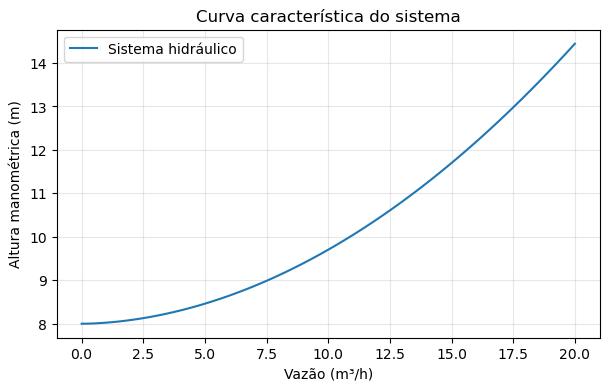

In [24]:
def altura_sistema(Q, D=0.05, L=30.0, dz=8.0, K=3.0,
                   rho=998.0, mu=0.001, eps=0.000045, g=9.81):
    if Q < 0:
        raise ValueError("Este modelo considera apenas vazões não negativas.")
    if Q == 0:
        return dz
    A = np.pi*D**2/4
    velocidade = Q/A
    re = rho*velocidade*D/mu
    f = fator_atrito_darcy(re, eps, D)
    return dz+(f*L/D+K)*velocidade**2/(2*g)

vazoes_m3h = np.linspace(0, 20, 81)
H_sistema = np.array([altura_sistema(q/3600) for q in vazoes_m3h])
fig, ax = plt.subplots(figsize=(7,4))
ax.plot(vazoes_m3h,H_sistema, label="Sistema hidráulico")
ax.set(xlabel="Vazão (m³/h)",ylabel="Altura manométrica (m)",title="Curva característica do sistema")
ax.grid(True,alpha=0.3);ax.legend();plt.show()

<div id="secao-11" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">11. Potência hidráulica e rendimento da bomba</div>

A potência hidráulica fornecida ao fluido é

$$P_h=\rho gQH.$$

Se o rendimento global da bomba for $\eta$, a potência mecânica requerida no eixo é $P_{eixo}=P_h/\eta$. Para $Q=12$ m³/h, $H=15$ m e $\eta=0{,}70$, o cálculo manual fornece

$$P_h\approx998(9{,}81)(12/3600)(15)\approx490\ \mathrm{W},$$

$$P_{eixo}\approx490/0{,}70\approx700\ \mathrm{W}.$$

A potência elétrica absorvida pode ser maior, devido às perdas no motor e no acionamento. Não se deve escolher um motor apenas com base neste cálculo simplificado.

In [25]:
Q = 12/3600
H = 15.0
eta = 0.70
P_h = rho*g*Q*H
P_eixo = P_h/eta
print(f"Potência hidráulica: {P_h:.1f} W")
print(f"Potência no eixo: {P_eixo:.1f} W")

Potência hidráulica: 489.5 W
Potência no eixo: 699.3 W


<div id="secao-12" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">12. Curva da bomba e ponto de operação</div>

O ponto de operação ocorre na interseção da curva da bomba $H_b(Q)$ com a curva do sistema $H_s(Q)$. Como aproximação didática, considere uma curva de bomba

$$H_b(Q)=24-0{,}035Q^2,$$

com $H$ em metros e **$Q$ em m³/h**. Essa equação é hipotética, não representa uma bomba comercial. O ponto de operação satisfaz $F(Q)=H_b(Q)-H_s(Q)=0$.

**Procedimento:** localizar um intervalo com mudança de sinal e aplicar bisseção. Isso relaciona diretamente os métodos numéricos estudados no Notebook 15 com um problema realista de Mecânica dos Fluidos. O ponto encontrado não garante operação segura: cavitação, NPSH, faixa de rendimento e limites do fabricante precisam ser verificados separadamente.

Ponto de operação: Q=17.670 m³/h, H=13.072 m
Resíduo de altura: 1.776e-15 m


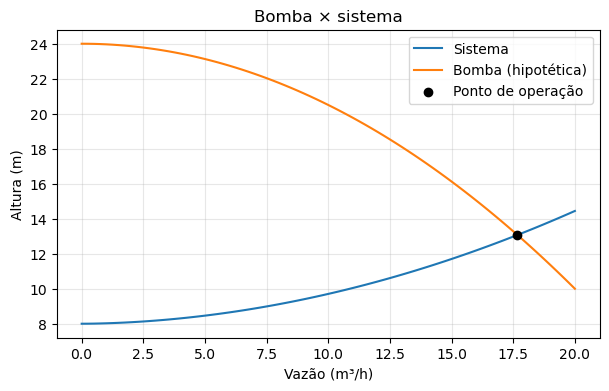

In [26]:
def altura_bomba(q_m3h):
    return 24.0-0.035*q_m3h**2

def residuo_bomba(q_m3h):
    return altura_bomba(q_m3h)-altura_sistema(q_m3h/3600)

a, b = 0.0, 20.0
assert residuo_bomba(a)*residuo_bomba(b)<0
for _ in range(80):
    meio = (a+b)/2
    if residuo_bomba(a)*residuo_bomba(meio)<=0:
        b=meio
    else:
        a=meio
Q_operacao=(a+b)/2
H_operacao=altura_bomba(Q_operacao)
print(f"Ponto de operação: Q={Q_operacao:.3f} m³/h, H={H_operacao:.3f} m")
print(f"Resíduo de altura: {residuo_bomba(Q_operacao):.3e} m")
fig,ax=plt.subplots(figsize=(7,4))
ax.plot(vazoes_m3h,H_sistema,label="Sistema")
ax.plot(vazoes_m3h,altura_bomba(vazoes_m3h),label="Bomba (hipotética)")
ax.scatter([Q_operacao],[H_operacao],color="black",zorder=3,label="Ponto de operação")
ax.set(xlabel="Vazão (m³/h)",ylabel="Altura (m)",title="Bomba × sistema")
ax.grid(True,alpha=0.3);ax.legend();plt.show()

<div id="secao-13" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">13. Tubulações em série e em paralelo</div>

**Tubulações em série:** a mesma vazão atravessa todos os trechos e as perdas de carga são somadas, $h_{L,total}=\sum h_{L,i}$.

**Tubulações em paralelo:** a perda de carga entre os nós comuns é igual para cada ramal, enquanto as vazões se somam: $Q_{total}=\sum Q_i$.

**Exemplo manual em série:** se dois trechos apresentam perdas de 1,2 m e 0,8 m para uma dada vazão, a perda total é 2,0 m. Para ramais em paralelo, não se deve simplesmente dividir a vazão igualmente, a menos que a simetria hidráulica justifique essa hipótese.

In [27]:
perdas_serie = np.array([1.2,0.8])
print(f"Perda total em série: {np.sum(perdas_serie):.2f} m")

# Dois ramais paralelos idealizados: h = a_i Q_i², Q em m³/h.
a1,a2=0.08,0.18
Q_total=12.0
# Mesma perda: a1*Q1²=a2*Q2² e Q1+Q2=Q_total.
Q1=Q_total*np.sqrt(a2)/(np.sqrt(a1)+np.sqrt(a2))
Q2=Q_total-Q1
print(f"Ramais: Q1={Q1:.2f}, Q2={Q2:.2f} m³/h")
print(f"Perdas: h1={a1*Q1**2:.3f}, h2={a2*Q2**2:.3f} m")

Perda total em série: 2.00 m
Ramais: Q1=7.20, Q2=4.80 m³/h
Perdas: h1=4.147, h2=4.147 m


<div id="secao-14" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">14. Análise de sensibilidade e dimensionamento</div>

A perda distribuída depende fortemente do diâmetro. Para uma vazão fixa, $v\propto D^{-2}$; portanto, mantendo $f_D$ aproximadamente constante, $h_f\propto D^{-5}$. Essa relação aproximada evidencia por que pequenas alterações no diâmetro podem produzir mudanças importantes na perda de carga.

Entretanto, aumentar o diâmetro também altera custo, volume de fluido e condições de operação. Dimensionar exige comparar alternativas técnicas e econômicas, não apenas minimizar a perda de carga.

In [28]:
diametros=np.array([0.04,0.05,0.06,0.07])
Q_ref=12/3600
for diam in diametros:
    velocidade=4*Q_ref/(np.pi*diam**2)
    re=rho*velocidade*diam/mu
    f=fator_atrito_darcy(re,rugosidade,diam)
    perda=f*(30/diam)*velocidade**2/(2*g)
    print(f"D={diam:.3f} m | v={velocidade:.2f} m/s | hf={perda:.2f} m")

D=0.040 m | v=2.65 m/s | hf=6.09 m
D=0.050 m | v=1.70 m/s | hf=1.97 m
D=0.060 m | v=1.18 m/s | hf=0.79 m
D=0.070 m | v=0.87 m/s | hf=0.37 m


<div id="secao-15" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">15. Simulação de esvaziamento de reservatório</div>

**Problema dinâmico:** um reservatório de seção transversal constante $A_T$ esvazia por uma saída idealizada de área $A_o$, sob ação da gravidade. Desprezando perdas e admitindo coeficiente de descarga constante $C_d$, a vazão é

$$Q_{out}=C_dA_o\sqrt{2gh}.$$

Pelo balanço de volume, $A_T\,dh/dt=-Q_{out}$, de modo que

$$\frac{dh}{dt}=-\frac{C_dA_o}{A_T}\sqrt{2gh}.$$

**Primeiro passo manual:** com $A_T=1$ m², $A_o=0{,}001$ m², $C_d=0{,}62$, $h_0=2$ m e $\Delta t=10$ s, a vazão inicial é aproximadamente $0{,}00388$ m³/s e a queda de nível no primeiro passo de Euler é aproximadamente $0{,}0388$ m. O modelo deixa de ser válido após o esvaziamento e ignora efeitos de entrada de ar e mudanças no coeficiente de descarga.

Nível inicial: 2.000 m; após 300 s: 1.000 m


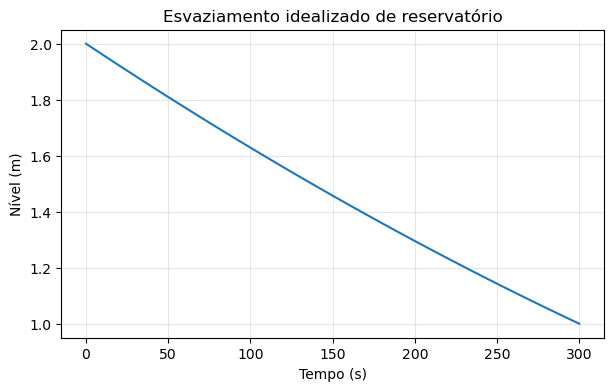

In [29]:
A_tanque=1.0
A_saida=0.001
Cd=0.62
passo_s=10.0
tempo_s=np.arange(0,301,passo_s)
h=np.empty(tempo_s.size)
h[0]=2.0
for i in range(len(h)-1):
    Q_saida=Cd*A_saida*np.sqrt(2*g*max(h[i],0.0))
    h[i+1]=max(0.0,h[i]-passo_s*Q_saida/A_tanque)
print(f"Nível inicial: {h[0]:.3f} m; após 300 s: {h[-1]:.3f} m")
fig,ax=plt.subplots(figsize=(7,4))
ax.plot(tempo_s,h)
ax.set(xlabel="Tempo (s)",ylabel="Nível (m)",title="Esvaziamento idealizado de reservatório")
ax.grid(True,alpha=0.3);plt.show()

<div id="secao-16" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">16. Validação, limitações e segurança de projeto</div>

Antes de confiar em uma simulação, verifique **unidades, conservação de massa, limites de operação, consistência das propriedades e domínio das correlações**. Um resultado numérico não valida automaticamente as hipóteses do modelo.

Para projetos de bombeamento, devem ser avaliados também **NPSH disponível e requerido, risco de cavitação, pressão máxima admissível, transientes hidráulicos (golpe de aríete), materiais, temperatura, segurança e documentação do fabricante**. Os exemplos deste notebook não substituem procedimentos de projeto, normas ou ensaios.

Também é importante distinguir **pressão** (Pa), **carga de pressão** ($p/\rho g$, em metros) e **altura manométrica** (m). Misturar essas grandezas é um erro dimensional frequente.

In [30]:
# Verificações básicas dos resultados produzidos neste notebook
assert Q_operacao>0
assert H_operacao>0
assert abs(residuo_bomba(Q_operacao))<1e-8
assert np.all(h>=0)
assert np.all(np.diff(h)<=1e-12)
assert np.isclose(Q1+Q2,Q_total)
print("Verificações físicas e numéricas básicas: aprovadas.")

Verificações físicas e numéricas básicas: aprovadas.


<div id="secao-17" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">17. Exercícios de consolidação</div>

**Exercício 1 — Vazão e velocidade.** Calcule a velocidade média para $Q=8$ m³/h em tubos com diâmetros internos de 40, 50 e 60 mm. Resolva manualmente um caso antes de utilizar Python.

**Exercício 2 — Reynolds.** Para água com $\rho=998$ kg/m³ e $\mu=0{,}001$ Pa·s, determine $Re$ para as velocidades de 0,05; 0,10; 0,20 e 0,50 m/s em tubo de 25 mm. Interprete os regimes indicativos.

**Exercício 3 — Darcy–Weisbach.** Estime a perda distribuída para $L=40$ m, $D=0{,}05$ m, $v=1{,}5$ m/s e $f_D=0{,}025$. Explique a unidade do resultado.

**Exercício 4 — Acessórios.** Uma linha apresenta $K_{total}=4{,}5$. Calcule a perda localizada para $v=1{,}8$ m/s.

**Exercício 5 — Energia mecânica.** Dois reservatórios abertos possuem desnível de 12 m e perdas totais de 4 m. Determine a altura que a bomba deve fornecer nas hipóteses adotadas.

**Exercício 6 — Bombeamento.** Calcule a potência hidráulica para $Q=10$ m³/h e $H=20$ m. Determine a potência no eixo para rendimento de 65%.

**Exercício 7 — Sensibilidade.** Compare a perda de carga para dois diâmetros internos, mantendo vazão e comprimento fixos. Discuta por que o fator de atrito pode mudar.

**Exercício 8 — Simulação dinâmica.** Modifique a área de saída do reservatório de 0,001 para 0,0015 m². Compare a evolução do nível e explique fisicamente a diferença.

**Desafio integrador:** construa uma nova curva hipotética de bomba $H_b(Q)=28-0{,}05Q^2$ (com $Q$ em m³/h) e encontre numericamente seu ponto de operação com a curva do sistema. Avalie se o resultado está dentro do intervalo usado no cálculo e explique quais informações adicionais seriam necessárias para selecionar uma bomba real.

<div id="secao-18" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">18. Conclusões</div>

Neste notebook, partimos da conservação de massa e da energia mecânica para calcular velocidades, regimes de escoamento, perdas distribuídas e localizadas, curvas hidráulicas e potência de bombeamento. Também construímos uma simulação dinâmica simples de reservatório.

A principal aprendizagem é que **Python automatiza cálculos, mas a Engenharia define as equações, as hipóteses e os critérios de interpretação**. O próximo notebook aprofundará a Transferência de Calor, relacionando fenômenos térmicos, modelos matemáticos e simulação computacional.

<div style="text-align: center; font-size: 12px; color: gray; margin-top: 40px; padding-top: 15px; border-top: 1px solid #dddddd;">
Material desenvolvido pelo Grupo de Pesquisas em Modelagem Computacional da UESC.<br>
© 2026 — Todos os direitos reservados. Uso comercial somente mediante autorização.
</div>